In [1]:
import pandas as pd

import numpy as np

from sklearn.decomposition import NMF

import warnings
warnings.filterwarnings("ignore")

from sklearn.cluster import KMeans

import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors

In [2]:
df = pd.read_csv("spotify.xls", index_col=[0])

In [3]:
df.head()

,song_1,song_2,song_3,song_4,song_5,song_6,song_7,song_8,song_9,song_10,...,song_4991,song_4992,song_4993,song_4994,song_4995,song_4996,song_4997,song_4998,song_4999,song_5000
user_1,2,2,8,8,13,1,4,9,1,2,...,14,2,14,1,9,0,11,6,14,7
user_2,13,5,5,5,12,8,10,10,2,2,...,10,6,11,1,1,5,12,8,3,0
user_3,3,9,2,8,0,1,11,7,3,7,...,9,5,7,15,12,13,14,5,0,14
user_4,2,6,7,8,14,0,12,7,8,1,...,9,15,9,14,10,6,11,13,6,0
user_5,11,12,8,6,13,7,0,7,3,13,...,12,14,11,11,11,7,3,6,11,7


In [4]:
df.shape

(1000, 5000)

In [5]:
# To get all the values

x = df.values

In [6]:
x

array([[ 2,  2,  8, ...,  6, 14,  7],
       [13,  5,  5, ...,  8,  3,  0],
       [ 3,  9,  2, ...,  5,  0, 14],
       ...,
       [ 6,  2,  1, ..., 13,  6, 13],
       [ 7,  0,  8, ..., 11,  9, 12],
       [ 6, 15,  0, ..., 15,  4,  5]], dtype=int64)

In [7]:
# Factorization

nmf = NMF(n_components=100, max_iter=1000,random_state=50) 

In [8]:
nmf.fit(x)

NMF(max_iter=1000, n_components=100, random_state=50)

In [9]:
user_matrix = nmf.transform(x)

In [10]:
user_matrix

array([[1.64352405e+00, 0.00000000e+00, 0.00000000e+00, ...,
        1.55121821e+00, 0.00000000e+00, 1.39500084e+00],
       [7.54190811e-01, 0.00000000e+00, 6.88828544e-01, ...,
        0.00000000e+00, 2.17391321e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       ...,
       [3.15417002e-03, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 1.95663537e+00, 0.00000000e+00],
       [3.61076915e-01, 3.49193923e+00, 5.27022338e+00, ...,
        0.00000000e+00, 2.39965713e-01, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00]])

In [11]:
# Take transpose to match the no of columnn in user_matrix

song_matrix = nmf.components_.T

In [12]:
song_matrix

array([[0.04910949, 0.06390182, 0.21756605, ..., 0.15085552, 0.        ,
        0.01510158],
       [0.        , 0.03355923, 0.02204165, ..., 0.25703291, 0.16546907,
        0.04358547],
       [0.41698986, 0.10718931, 0.0365846 , ..., 0.24300262, 0.16717202,
        0.29558707],
       ...,
       [0.21898823, 0.        , 0.01726316, ..., 0.0453832 , 0.28768801,
        0.        ],
       [0.        , 0.05386013, 0.        , ..., 0.        , 0.        ,
        0.2757075 ],
       [0.35359683, 0.        , 0.15555796, ..., 0.        , 0.36269504,
        0.29614295]])

In [13]:
# 1000 users , songs of 100 different genres which the users listen to
user_matrix.shape

(1000, 100)

In [14]:
# 5000 songs , 100 genres
song_matrix.shape

(5000, 100)

In [15]:
# Steps for building a Recommendation System
# 1) Consider recommending songs to user_1 who is located at row location 0.
# 2) Find the Euclidean Distance between user_1 and the remaining 999 users.
# 3) Find out top n songs heard by the 5 closest users
# 4) Recommend those n songs to user_1.

In [16]:
# Calculating the distance between two users

def calculate_dist(u1,u2):
    return pow(sum([pow(u1[x]-u2[x],2) for x in range(len(u1))]) ,0.5)

In [17]:
calculate_dist(user_matrix[0],user_matrix[1])

14.083658929058961

In [18]:
# Calculating distance between the base user(user_1) and the other 999 users to find the nearest neighbours

def distance_from_user(base_user , user_matrix):
    
    distance = []
    for i in range(len(user_matrix)):
        if base_user != i:
            distance.append(calculate_dist(user_matrix[base_user],user_matrix[i]))
            
        else : 
            pass
        
    return distance

In [19]:
dist = distance_from_user(0,user_matrix)

In [20]:
dist

[14.083658929058961,
 12.214404873636774,
 12.685242015566809,
 13.00101583492593,
 12.667745416052249,
 12.932335284880185,
 14.07216933889725,
 15.017811943770429,
 14.25911772312922,
 13.810570955563048,
 14.469262006998429,
 12.065869758012019,
 11.772679868073523,
 12.15236888270032,
 12.63515856545652,
 15.224167490047229,
 12.502375276194305,
 12.956398015553807,
 11.91868155470653,
 11.50179443733502,
 12.293150336302034,
 14.82941636063756,
 13.659387211877771,
 14.909035422236535,
 12.164185977370632,
 13.746353871345104,
 12.605787083341106,
 12.905746558308257,
 14.821554575642441,
 11.466647394504141,
 13.364448565728887,
 15.800456369842077,
 13.38730469174962,
 12.155099665223876,
 14.02448139968903,
 13.204094643718363,
 15.688195893959808,
 14.323374496641106,
 12.314125857156302,
 10.192295637297464,
 14.254573301985598,
 15.746360828794115,
 13.426679086285535,
 11.896125511122083,
 14.125806472924834,
 11.470519357823276,
 11.913286062968075,
 10.22466486447674,
 11

In [21]:
# argsort--> to sort the data , displays position of the song

user_index = np.argsort(dist)[0:5]
user_index

array([ 39,  47, 830, 214, 456], dtype=int64)

In [22]:
temp = pd.DataFrame(df.iloc[user_index])[0:5]

In [23]:
temp

,song_1,song_2,song_3,song_4,song_5,song_6,song_7,song_8,song_9,song_10,...,song_4991,song_4992,song_4993,song_4994,song_4995,song_4996,song_4997,song_4998,song_4999,song_5000
user_40,8,2,10,9,2,0,6,4,2,10,...,1,14,4,14,3,10,0,10,11,7
user_48,14,0,15,15,12,3,8,1,0,7,...,12,0,11,2,14,5,12,12,12,10
user_831,8,3,1,0,14,10,14,14,2,9,...,15,12,7,8,9,4,14,10,9,1
user_215,12,8,8,1,9,14,2,3,2,13,...,5,4,6,13,5,14,4,5,10,8
user_457,2,13,4,9,13,2,1,12,0,3,...,11,5,12,3,11,9,11,11,10,11


In [24]:
for i in user_index:
    
    print("Songs heard by user" ,i+1)
    temp = pd.DataFrame(df.iloc[i])
    print(temp[temp.values != 0].index)

Songs heard by user 40
Index(['song_1', 'song_2', 'song_3', 'song_4', 'song_5', 'song_7', 'song_8',
       'song_9', 'song_10', 'song_11',
       ...
       'song_4990', 'song_4991', 'song_4992', 'song_4993', 'song_4994',
       'song_4995', 'song_4996', 'song_4998', 'song_4999', 'song_5000'],
      dtype='object', length=4731)
Songs heard by user 48
Index(['song_1', 'song_3', 'song_4', 'song_5', 'song_6', 'song_7', 'song_8',
       'song_10', 'song_11', 'song_12',
       ...
       'song_4990', 'song_4991', 'song_4993', 'song_4994', 'song_4995',
       'song_4996', 'song_4997', 'song_4998', 'song_4999', 'song_5000'],
      dtype='object', length=4696)
Songs heard by user 831
Index(['song_1', 'song_2', 'song_3', 'song_5', 'song_6', 'song_7', 'song_8',
       'song_9', 'song_10', 'song_11',
       ...
       'song_4991', 'song_4992', 'song_4993', 'song_4994', 'song_4995',
       'song_4996', 'song_4997', 'song_4998', 'song_4999', 'song_5000'],
      dtype='object', length=4660)
Songs he

In [25]:
# To recommend top 10 songs heard by these 5 closest users

def recommending_topsongs_heardByUsers(user_index,df):
    
    temp_df = df.iloc[user_index]
    dict1 = temp_df.max().to_dict()        # To sort in descending order and convert temp_df to dictionary
    sorted_dict = sorted(dict1.items(),key = lambda keyvalue:(keyvalue[1],keyvalue[0]),reverse=True)[0:10]    # To sort the dictionary dict1
     
    return [x[0] for x in sorted_dict]
    

In [26]:
recommending_topsongs_heardByUsers(user_index,df)

['song_999',
 'song_994',
 'song_986',
 'song_982',
 'song_973',
 'song_969',
 'song_966',
 'song_964',
 'song_963',
 'song_961']

In [27]:
# Recommendation System Type 2

In [28]:
wcss = {}
for k in range(1,50):
    k_means = KMeans(n_clusters=k,max_iter=100).fit(song_matrix)
    wcss[k] = k_means.inertia_

Text(0, 0.5, 'Mean Squared Error')

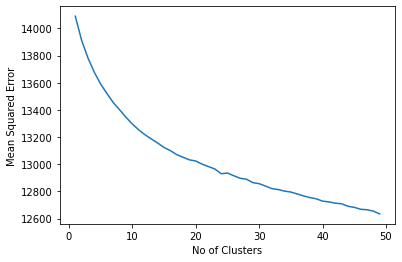

In [29]:
plt.plot(list(wcss.keys()),list(wcss.values()))
plt.xlabel("No of Clusters")
plt.ylabel("Mean Squared Error")

In [30]:
def recommend_songs_onBasis_of_cluster(df,no_of_clusters,song_matrix,song_name,n_recommendations):
    
    
    k_means = KMeans(n_clusters = no_of_clusters,max_iter= 1000).fit(song_matrix)
    index_of_song = df.columns.to_list().index(song_name)
    song_vector = song_matrix[index_of_song]
    all_other_songs = list(k_means.predict(song_matrix))
    songs_in_the_selected_cluster = [x for x in range(len(all_other_songs)) if all_other_songs[x] == k_means.predict([song_vector])]
    song_cluster = song_matrix[songs_in_the_selected_cluster]
    
    nn = NearestNeighbors(n_neighbors = n_recommendations)
    nn.fit(song_cluster)
    recommended_songs = nn.kneighbors([song_matrix[index_of_song]])
    
    col_list = list(df.columns)
    
    
    return [col_list[x] for x in  recommended_songs[1][0]]

In [31]:
recommend_songs_onBasis_of_cluster(df,11,song_matrix,"song_2",n_recommendations=5)

['song_1', 'song_415', 'song_284', 'song_204', 'song_143']